In [9]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import brentq
from scipy.integrate import quad

In [2]:
plt.style.use('seaborn-v0_8-whitegrid')
np.random.seed(42)

## F usual, F outlier, epsilon

In [3]:
MU_TRUE = 5.0
SIGMA_TRUE = 2.0
EPSILON = 0.10 # Доля выбросов (10%)
TAU = 10.0 # Масштаб выбросов N(0, tau^2)
N_SAMPLES = 1000

In [4]:
def sample_with_outliers(n, mu, sigma, eps, outlier_type='normal_scale', tau=10.0):
    # 1 - выброс, 0 - обычное
    is_outlier = np.random.binomial(1, eps, size=n)
    u_usual = np.random.normal(0, 1, size=n)

    if outlier_type == 'normal_scale':
        u_outlier = np.random.normal(0, tau, size=n)
    elif outlier_type == 'cauchy':
        u_outlier = np.random.standard_cauchy(size=n)
    else:
        raise ValueError("Неизвестный тип распределения выбросов")

    u = np.where(is_outlier == 0, u_usual, u_outlier)
    x = mu + sigma * u
    return x, u, is_outlier

In [5]:
x_clean, _, _ = sample_with_outliers(N_SAMPLES, MU_TRUE, SIGMA_TRUE, eps=0.0)
x_dirty, u_dirty, outliers_mask = sample_with_outliers(
    N_SAMPLES, MU_TRUE, SIGMA_TRUE, eps=EPSILON, outlier_type='normal_scale', tau=TAU
)

In [6]:
def print_metrics(x, label):
    mean_val = np.mean(x)
    med_val = np.median(x)
    std_val = np.std(x, ddof=1)
    madn_val = stats.median_abs_deviation(x, scale='normal') # Делит на ~0.67449

    print(f"=== {label} (Истинные: mu = {MU_TRUE}, sigma = {SIGMA_TRUE}) ===")
    print(f"Выборочное среднее: {mean_val:.4f} | Выборочная медиана: {med_val:.4f}")
    print(f"Стандартное откл. S: {std_val:.4f} | Оценка MADN:        {madn_val:.4f}\n")

In [7]:
print_metrics(x_clean, "Чистые данные (eps = 0)")
print_metrics(x_dirty, f"Данные с выбросами (eps = {EPSILON}, F_outlier = N(0, {TAU}^2))")

=== Чистые данные (eps = 0) (Истинные: mu = 5.0, sigma = 2.0) ===
Выборочное среднее: 5.1978 | Выборочная медиана: 5.1684
Стандартное откл. S: 1.9779 | Оценка MADN:        1.9381

=== Данные с выбросами (eps = 0.1, F_outlier = N(0, 10.0^2)) (Истинные: mu = 5.0, sigma = 2.0) ===
Выборочное среднее: 4.9697 | Выборочная медиана: 4.9201
Стандартное откл. S: 6.5928 | Оценка MADN:        2.2839



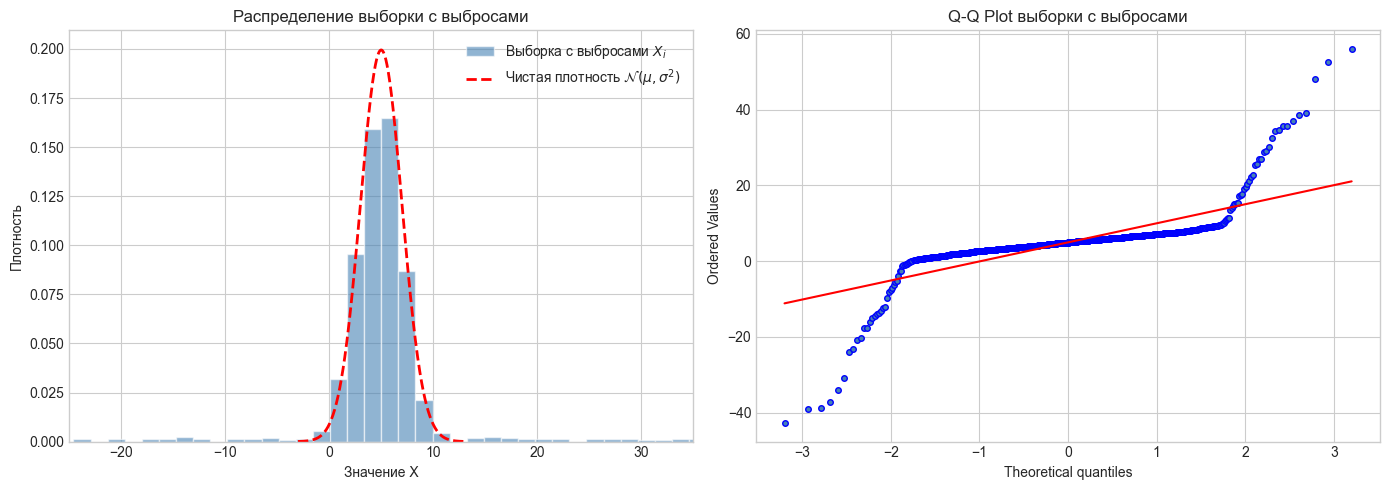

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(x_dirty, bins=60, density=True, alpha=0.6, color='steelblue', label='Выборка с выбросами $X_i$')
x_grid = np.linspace(MU_TRUE - 4*SIGMA_TRUE, MU_TRUE + 4*SIGMA_TRUE, 300)
axes[0].plot(x_grid, stats.norm.pdf(x_grid, MU_TRUE, SIGMA_TRUE), 'r--', lw=2, label=r'Чистая плотность $\mathcal{N}(\mu, \sigma^2)$')
axes[0].set_title('Распределение выборки с выбросами', fontsize=12)
axes[0].set_xlabel('Значение X')
axes[0].set_ylabel('Плотность')
axes[0].set_xlim(MU_TRUE - 15*SIGMA_TRUE, MU_TRUE + 15*SIGMA_TRUE)
axes[0].legend()

stats.probplot(x_dirty, dist="norm", plot=axes[1])
axes[1].set_title('Q-Q Plot выборки с выбросами', fontsize=12)
axes[1].get_lines()[0].set_markerfacecolor('steelblue')
axes[1].get_lines()[0].set_markersize(4.0)
axes[1].get_lines()[1].set_color('red')

plt.tight_layout()
plt.show()

## Оценки для sigma

In [10]:
def cdf_u(u, eps=EPSILON, tau=TAU):
    """Функция распределения F_U(u) = (1 - eps)*Phi(u) + eps*Phi(u/tau)"""
    return (1 - eps) * stats.norm.cdf(u, 0, 1) + eps * stats.norm.cdf(u, 0, tau)

In [11]:
def pdf_u(u, eps=EPSILON, tau=TAU):
    """Плотность распределения f_U(u)"""
    return (1 - eps) * stats.norm.pdf(u, 0, 1) + eps * stats.norm.pdf(u, 0, tau)

In [12]:
def quantile_u(p, eps=EPSILON, tau=TAU):
    """Численное нахождение квантиля F_U^{-1}(p)"""
    return brentq(lambda u: cdf_u(u, eps, tau) - p, -100 * tau, 100 * tau)

In [13]:
def rho_biscale(t, k=1.54764):
    t = np.asarray(t)
    abs_t = np.abs(t)
    res = np.ones_like(abs_t, dtype=float)
    mask = abs_t <= k
    res[mask] = 1.0 - (1.0 - (abs_t[mask] / k)**2)**3
    return res

In [14]:
K_BISCALE = 1.54764

# константы (для N(0,1))
C_MAD_STD = stats.norm.ppf(0.75) # ~ 0.67449
C_IQR_STD = 2.0 * stats.norm.ppf(0.75) # ~ 1.34898
DELTA_STD, _ = quad(lambda u: rho_biscale(u, K_BISCALE) * stats.norm.pdf(u, 0, 1), -np.inf, np.inf)

# константы (состоятельные для eps=0.10, tau=10)
C_MAD_MOD = quantile_u(0.75, EPSILON, TAU)
C_IQR_MOD = 2.0 * C_MAD_MOD
DELTA_MOD, _ = quad(lambda u: rho_biscale(u, K_BISCALE) * pdf_u(u, EPSILON, TAU), -np.inf, np.inf)

In [15]:
print(f"MAD: стандартная = {C_MAD_STD:.5f}, модифицированная = {C_MAD_MOD:.5f}")
print(f"IQR: стандартная = {C_IQR_STD:.5f}, модифицированная = {C_IQR_MOD:.5f}")
print(f"M-оценка: delta_std = {DELTA_STD:.5f}, delta_mod = {DELTA_MOD:.5f}\n")

MAD: стандартная = 0.67449, модифицированная = 0.75355
IQR: стандартная = 1.34898, модифицированная = 1.50710
M-оценка: delta_std = 0.50000, delta_mod = 0.54436



In [17]:
def calc_madn(x, c_mad=C_MAD_STD):
    med = np.median(x)
    return np.median(np.abs(x - med)) / c_mad

def calc_iqrn(x, c_iqr=C_IQR_STD):
    q75, q25 = np.percentile(x, [75, 25])
    return (q75 - q25) / c_iqr

def calc_m_scale(x, delta=DELTA_STD, k=K_BISCALE):
    """Нахождение M-оценки масштаба решением уравнения mean(rho((x - med)/s)) = delta"""
    med = np.median(x)
    r = np.abs(x - med)
    if np.all(r == 0):
        return 0.0
    obj = lambda s: np.mean(rho_biscale(r / s, k=k)) - delta
    return brentq(obj, 1e-6, np.max(r) * 10)

In [18]:
a_test, c_test = -3.5, 12.0
x_transformed = a_test * x_dirty + c_test

In [20]:
print("Проверка эквивариантности: sigma_hat(a*X + c) == |a| * sigma_hat(X)")
for name, func in [("MADN", calc_madn), ("IQRN", calc_iqrn), ("M-scale (biscale)", calc_m_scale)]:
    val_orig = func(x_dirty)
    val_trans = func(x_transformed)
    val_expected = np.abs(a_test) * val_orig
    diff = np.abs(val_trans - val_expected)
    print(f"{name}: |a|*sigma(X) = {val_expected:.6f}, sigma(aX+c) = {val_trans:.6f} (разница: {diff:.2e})")

Проверка эквивариантности: sigma_hat(a*X + c) == |a| * sigma_hat(X)
MADN: |a|*sigma(X) = 7.993722, sigma(aX+c) = 7.993722 (разница: 2.66e-15)
IQRN: |a|*sigma(X) = 7.905005, sigma(aX+c) = 7.905005 (разница: 1.78e-15)
M-scale (biscale): |a|*sigma(X) = 7.880391, sigma(aX+c) = 7.880391 (разница: 8.88e-16)


## Вычисление M-оценки для mu, теоретических и эмпирических дисперсий

In [21]:
def psi_huber(t, k):
    return np.clip(t, -k, k)

def dpsi_huber(t, k):
    return (np.abs(t) <= k).astype(float)

def weight_huber(t, k):
    t = np.asarray(t, dtype=float)
    abs_t = np.abs(t)
    w = np.ones_like(t)
    mask = abs_t > k
    w[mask] = k / abs_t[mask]
    return w

def psi_bisquare(t, k):
    t = np.asarray(t, dtype=float)
    res = np.zeros_like(t)
    mask = np.abs(t) <= k
    res[mask] = t[mask] * (1.0 - (t[mask] / k)**2)**2
    return res

def dpsi_bisquare(t, k):
    t = np.asarray(t, dtype=float)
    res = np.zeros_like(t)
    mask = np.abs(t) <= k
    u2 = (t[mask] / k)**2
    res[mask] = (1.0 - u2) * (1.0 - 5.0 * u2)
    return res

def weight_bisquare(t, k):
    t = np.asarray(t, dtype=float)
    w = np.zeros_like(t)
    mask = np.abs(t) <= k
    w[mask] = (1.0 - (t[mask] / k)**2)**2
    return w

In [22]:
# для нахождения M-оценки mu при заданном sigma_hat
def calc_m_location_irls(x, sigma_hat, weight_func, k, max_iter=100, tol=1e-7):
    mu_curr = np.median(x)
    for _ in range(max_iter):
        r = (x - mu_curr) / sigma_hat
        w = weight_func(r, k)
        w_sum = np.sum(w)
        if w_sum == 0:
            break
        mu_next = np.sum(w * x) / w_sum
        if np.abs(mu_next - mu_curr) < tol:
            return mu_next
        mu_curr = mu_next
    return mu_curr

In [23]:
# расчет теоретической асимптотической дисперсии
def asymptotic_var_theory(psi_func, dpsi_func, k, sigma=SIGMA_TRUE, eps=EPSILON, tau=TAU):
    # E[psi^2(U)]
    num, _ = quad(lambda u: (psi_func(u, k)**2) * pdf_u(u, eps, tau), -k, k, limit=100)
    if psi_func == psi_huber:
        # для функции Губера добавляем хвосты |u| > k, где psi^2(u) = k^2
        tail_prob = 2.0 * (1.0 - cdf_u(k, eps, tau))
        num += (k**2) * tail_prob
    # знаменатель: (E[psi'(U)])^2
    den_val, _ = quad(lambda u: dpsi_func(u, k) * pdf_u(u, eps, tau), -k, k, limit=100)
    return (sigma**2) * num / (den_val**2)

In [24]:
# сравнение при различных параметрах k
k_huber_list = [0.7, 1.0, 1.345, 1.7, 2.0]
k_bisq_list = [3.0, 4.0, 4.685, 5.5, 6.0]

n_mc = 400
n_size = 1000
np.random.seed(42)

In [25]:
samples_mc = []
sigmas_mc = []
for _ in range(n_mc):
    x_sim, _, _ = sample_with_outliers(n_size, MU_TRUE, SIGMA_TRUE, EPSILON, 'normal_scale', TAU)
    s_hat = calc_m_scale(x_sim, DELTA_MOD, K_BISCALE)
    samples_mc.append(x_sim)
    sigmas_mc.append(s_hat)

In [27]:
print("Оценки Губера для параметра mu (истинное mu = 5.0):")
huber_theory_vars = []
huber_emp_vars = []
for k in k_huber_list:
    v_th = asymptotic_var_theory(psi_huber, dpsi_huber, k)
    est_mc = [calc_m_location_irls(samples_mc[i], sigmas_mc[i], weight_huber, k) for i in range(n_mc)]
    v_emp = n_size * np.var(est_mc)
    est_single = calc_m_location_irls(x_dirty, calc_m_scale(x_dirty, DELTA_MOD, K_BISCALE), weight_huber, k)
    huber_theory_vars.append(v_th)
    huber_emp_vars.append(v_emp)
    print(f"k = {k:.3f}, mu_hat = {est_single:.4f}, Асимпт. дисперсия (теория) = {v_th:.4f}, n*Var (эмпирическое) = {v_emp:.4f}")

Оценки Губера для параметра mu (истинное mu = 5.0):
k = 0.700, mu_hat = 4.9228, Асимпт. дисперсия (теория) = 6.0036, n*Var (эмпирическое) = 6.1206
k = 1.000, mu_hat = 4.9189, Асимпт. дисперсия (теория) = 5.7738, n*Var (эмпирическое) = 5.9260
k = 1.345, mu_hat = 4.9112, Асимпт. дисперсия (теория) = 5.7406, n*Var (эмпирическое) = 5.8561
k = 1.700, mu_hat = 4.9005, Асимпт. дисперсия (теория) = 5.9149, n*Var (эмпирическое) = 6.0267
k = 2.000, mu_hat = 4.8974, Асимпт. дисперсия (теория) = 6.1982, n*Var (эмпирическое) = 6.3101


In [29]:
print("\nОценки bisquare для параметра mu (истинное mu = 5.0):")
bisq_theory_vars = []
bisq_emp_vars = []
for k in k_bisq_list:
    v_th = asymptotic_var_theory(psi_bisquare, dpsi_bisquare, k)
    est_mc = [calc_m_location_irls(samples_mc[i], sigmas_mc[i], weight_bisquare, k) for i in range(n_mc)]
    v_emp = n_size * np.var(est_mc)
    est_single = calc_m_location_irls(x_dirty, calc_m_scale(x_dirty, DELTA_MOD, K_BISCALE), weight_bisquare, k)
    bisq_theory_vars.append(v_th)
    bisq_emp_vars.append(v_emp)
    print(f"k = {k:.3f}, mu_hat = {est_single:.4f}, Асимпт. дисперсия (теория) = {v_th:.4f}, n*Var (эмпирическое) = {v_emp:.4f}")


Оценки bisquare для параметра mu (истинное mu = 5.0):
k = 3.000, mu_hat = 4.9234, Асимпт. дисперсия (теория) = 5.8941, n*Var (эмпирическое) = 5.8092
k = 4.000, mu_hat = 4.8977, Асимпт. дисперсия (теория) = 5.0733, n*Var (эмпирическое) = 5.0199
k = 4.685, mu_hat = 4.8888, Асимпт. дисперсия (теория) = 4.9238, n*Var (эмпирическое) = 4.8989
k = 5.500, mu_hat = 4.8839, Асимпт. дисперсия (теория) = 4.9035, n*Var (эмпирическое) = 4.8806
k = 6.000, mu_hat = 4.8837, Асимпт. дисперсия (теория) = 4.9370, n*Var (эмпирическое) = 4.9100


In [30]:
# проверим усеченное среднее (L-оценку) и медиану
med_mc = [np.median(s) for s in samples_mc]
trim_mc = [stats.trim_mean(s, proportiontocut=0.10) for s in samples_mc]
v_med_th = (SIGMA_TRUE**2) / (4.0 * (pdf_u(0, EPSILON, TAU)**2))
print("\nБазовые и L-оценки для сравнения:")
print(f"Медиана: mu_hat = {np.median(x_dirty):.4f}, Асимпт. дисперсия (теория) = {v_med_th:.4f}, n*Var (эмпирика) = {n_size * np.var(med_mc):.4f}")
print(f"Усеченное среднее (alpha=0.10): mu_hat = {stats.trim_mean(x_dirty, 0.10):.4f}, n*Var (эмпирика) = {n_size * np.var(trim_mc):.4f}")


Базовые и L-оценки для сравнения:
Медиана: mu_hat = 4.9201, Асимпт. дисперсия (теория) = 7.5875, n*Var (эмпирика) = 7.3933
Усеченное среднее (alpha=0.10): mu_hat = 4.9066, n*Var (эмпирика) = 5.9207


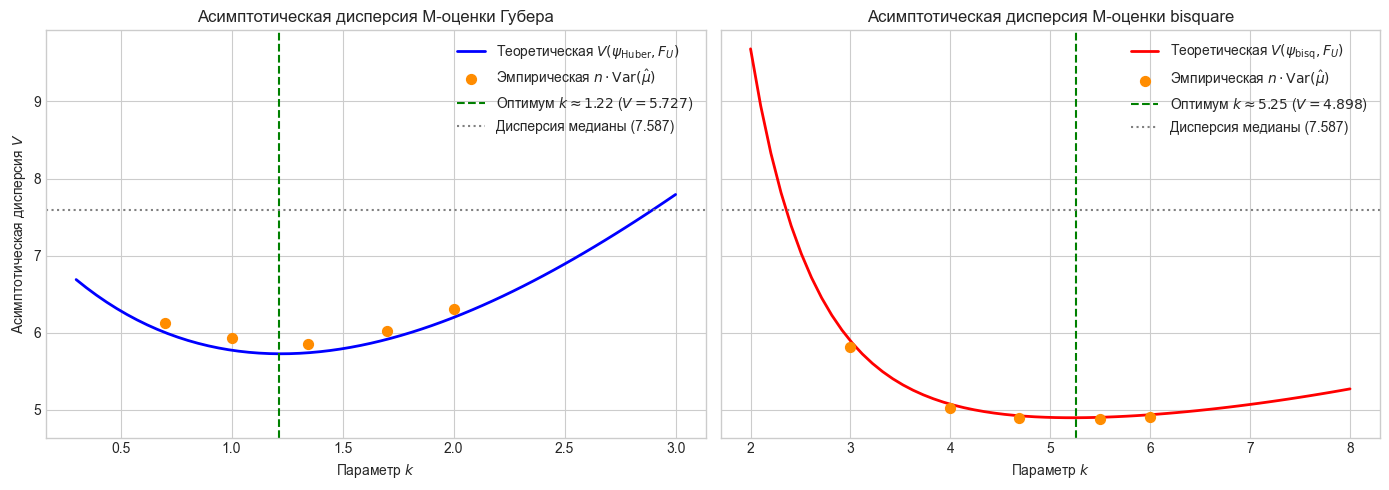

In [31]:
k_grid_huber = np.linspace(0.3, 3.0, 60)
v_grid_huber = [asymptotic_var_theory(psi_huber, dpsi_huber, k) for k in k_grid_huber]
best_idx_h = np.argmin(v_grid_huber)

k_grid_bisq = np.linspace(2.0, 8.0, 60)
v_grid_bisq = [asymptotic_var_theory(psi_bisquare, dpsi_bisquare, k) for k in k_grid_bisq]
best_idx_b = np.argmin(v_grid_bisq)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# функция Губера
axes[0].plot(k_grid_huber, v_grid_huber, 'b-', lw=2, label='Теоретическая $V(\\psi_{\\text{Huber}}, F_U)$')
axes[0].scatter(k_huber_list, huber_emp_vars, color='darkorange', zorder=5, s=50, label='Эмпирическая $n \\cdot \\text{Var}(\\hat{\\mu})$')
axes[0].axvline(k_grid_huber[best_idx_h], color='green', linestyle='--', label=f'Оптимум $k \\approx {k_grid_huber[best_idx_h]:.2f}$ ($V = {v_grid_huber[best_idx_h]:.3f}$)')
axes[0].axhline(v_med_th, color='gray', linestyle=':', label=f'Дисперсия медианы ({v_med_th:.3f})')
axes[0].set_title('Асимптотическая дисперсия M-оценки Губера', fontsize=12)
axes[0].set_xlabel('Параметр $k$')
axes[0].set_ylabel('Асимптотическая дисперсия $V$')
axes[0].legend()

# bisquare
axes[1].plot(k_grid_bisq, v_grid_bisq, 'r-', lw=2, label='Теоретическая $V(\\psi_{\\text{bisq}}, F_U)$')
axes[1].scatter(k_bisq_list, bisq_emp_vars, color='darkorange', zorder=5, s=50, label='Эмпирическая $n \\cdot \\text{Var}(\\hat{\\mu})$')
axes[1].axvline(k_grid_bisq[best_idx_b], color='green', linestyle='--', label=f'Оптимум $k \\approx {k_grid_bisq[best_idx_b]:.2f}$ ($V = {v_grid_bisq[best_idx_b]:.3f}$)')
axes[1].axhline(v_med_th, color='gray', linestyle=':', label=f'Дисперсия медианы ({v_med_th:.3f})')
axes[1].set_title('Асимптотическая дисперсия M-оценки bisquare', fontsize=12)
axes[1].set_xlabel('Параметр $k$')
axes[1].legend()

plt.tight_layout()
plt.show()

## Одновременное оценивание параметров

In [32]:
def weight_step(t, k):
    return (np.abs(t) <= k).astype(float)

def rho_huber_scale(t, k=1.345):
    return np.minimum(np.asarray(t, dtype=float)**2, k**2)

def rho_step_scale(t, k=1.0):
    return (np.abs(t) > k).astype(float)

In [33]:
K_HUBER_S = 1.345
K_STEP_S = 1.0

DELTA_MOD_BISCALE = DELTA_MOD
DELTA_MOD_HUBER, _ = quad(lambda u: rho_huber_scale(u, K_HUBER_S) * pdf_u(u, EPSILON, TAU), -np.inf, np.inf)
DELTA_MOD_STEP = 2.0 * (1.0 - cdf_u(K_STEP_S, EPSILON, TAU))

print("Константы delta_mod для функций масштаба:")
print(f"Biscale (k={K_BISCALE}): delta_mod = {DELTA_MOD_BISCALE:.5f}")
print(f"Huber scale (k={K_HUBER_S}): delta_mod = {DELTA_MOD_HUBER:.5f}")
print(f"Step scale (k={K_STEP_S}): delta_mod = {DELTA_MOD_STEP:.5f}\n")

Константы delta_mod для функций масштаба:
Biscale (k=1.54764): delta_mod = 0.54436
Huber scale (k=1.345): delta_mod = 0.80713
Step scale (k=1.0): delta_mod = 0.37761



In [39]:
def joint_m_estimator(x, weight_loc_func, k_loc, rho_scale_func, k_scale, delta_scale, init_mu=None, init_sigma=None, max_iter=100, tol=1e-7):
    mu_curr = np.median(x) if init_mu is None else float(init_mu)
    sigma_curr = calc_madn(x, C_MAD_MOD) if init_sigma is None else float(init_sigma)

    history_mu = [mu_curr]
    history_sigma = [sigma_curr]

    for _ in range(max_iter):
        # обновление mu через веса
        r = (x - mu_curr) / sigma_curr
        w = weight_loc_func(r, k_loc)
        w_sum = np.sum(w)
        mu_next = np.sum(w * x) / w_sum if w_sum > 0 else mu_curr

        # обновление sigma относительно нового mu_next
        abs_diff = np.abs(x - mu_next)
        if rho_scale_func == rho_step_scale:
            # sigma определяется через квантиль порядка (1 - delta_scale)
            sigma_next = np.quantile(abs_diff, 1.0 - delta_scale) / k_scale
        else:
            # непрерывные функции тогда решаем уравнение mean(rho_scale(|x - mu_next| / s)) = delta_scale
            obj = lambda s: np.mean(rho_scale_func(abs_diff / s, k_scale)) - delta_scale
            sigma_next = brentq(obj, 1e-5, np.max(abs_diff) * 10.0)

        history_mu.append(mu_next)
        history_sigma.append(sigma_next)

        if np.abs(mu_next - mu_curr) + np.abs(sigma_next - sigma_curr) < tol:
            break

        mu_curr, sigma_curr = mu_next, sigma_next

    return mu_curr, sigma_curr, np.array(history_mu), np.array(history_sigma)

In [35]:
loc_configs = [
    ("Huber (k=1.345)", weight_huber, 1.345),
    ("Bisquare (k=4.685)", weight_bisquare, 4.685),
    ("Step (k=2.500)", weight_step, 2.500)
]

scale_configs = [
    ("Biscale (k=1.55)", rho_biscale, K_BISCALE, DELTA_MOD_BISCALE),
    ("Huber-scale (k=1.35)", rho_huber_scale, K_HUBER_S, DELTA_MOD_HUBER),
    ("Step-scale (k=1.00)", rho_step_scale, K_STEP_S, DELTA_MOD_STEP)
]

print(f"Одновременное оценивание на выборке x_dirty (истинные: mu = {MU_TRUE}, sigma = {SIGMA_TRUE}):")
for loc_name, w_func, k_l in loc_configs:
    for sc_name, r_func, k_s, d_s in scale_configs:
        mu_est, sig_est, h_mu, _ = joint_m_estimator(x_dirty, w_func, k_l, r_func, k_s, d_s)
        print(f"psi: {loc_name}, rho_scale: {sc_name} -> mu_hat = {mu_est:.4f}, sigma_hat = {sig_est:.4f} (шагов: {len(h_mu)-1})")

Одновременное оценивание на выборке x_dirty (истинные: mu = 5.0, sigma = 2.0):
psi: Huber (k=1.345), rho_scale: Biscale (k=1.55) -> mu_hat = 4.9112, sigma_hat = 2.0044 (шагов: 7)
psi: Huber (k=1.345), rho_scale: Huber-scale (k=1.35) -> mu_hat = 4.9119, sigma_hat = 1.9798 (шагов: 7)
psi: Huber (k=1.345), rho_scale: Step-scale (k=1.00) -> mu_hat = 4.9120, sigma_hat = 1.9778 (шагов: 7)
psi: Bisquare (k=4.685), rho_scale: Biscale (k=1.55) -> mu_hat = 4.8888, sigma_hat = 2.0055 (шагов: 9)
psi: Bisquare (k=4.685), rho_scale: Huber-scale (k=1.35) -> mu_hat = 4.8894, sigma_hat = 1.9811 (шагов: 9)
psi: Bisquare (k=4.685), rho_scale: Step-scale (k=1.00) -> mu_hat = 4.8896, sigma_hat = 1.9752 (шагов: 9)
psi: Step (k=2.500), rho_scale: Biscale (k=1.55) -> mu_hat = 4.8830, sigma_hat = 2.0059 (шагов: 3)
psi: Step (k=2.500), rho_scale: Huber-scale (k=1.35) -> mu_hat = 4.8830, sigma_hat = 1.9815 (шагов: 3)
psi: Step (k=2.500), rho_scale: Step-scale (k=1.00) -> mu_hat = 4.8830, sigma_hat = 1.9807 (шаго

In [40]:
n_mc_joint = 300
n_size_joint = 1000
np.random.seed(42)

selected_pairs = [
    ("Median + MADN", None, None, None, None, None),
    ("Huber + Huber-scale", weight_huber, 1.345, rho_huber_scale, K_HUBER_S, DELTA_MOD_HUBER),
    ("Huber + Biscale", weight_huber, 1.345, rho_biscale, K_BISCALE, DELTA_MOD_BISCALE),
    ("Step + Step-scale", weight_step, 2.500, rho_step_scale, K_STEP_S, DELTA_MOD_STEP),
    ("Bisquare + Biscale", weight_bisquare, 4.685, rho_biscale, K_BISCALE, DELTA_MOD_BISCALE)
]

mc_results = {pair[0]: {'mu': [], 'sigma': []} for pair in selected_pairs}

for _ in range(n_mc_joint):
    x_sim, _, _ = sample_with_outliers(n_size_joint, MU_TRUE, SIGMA_TRUE, EPSILON, 'normal_scale', TAU)
    for label, w_func, k_l, r_func, k_s, d_s in selected_pairs:
        if w_func is None:
            m_val = np.median(x_sim)
            s_val = calc_madn(x_sim, C_MAD_MOD)
        else:
            m_val, s_val, _, _ = joint_m_estimator(x_sim, w_func, k_l, r_func, k_s, d_s)
        mc_results[label]['mu'].append(m_val)
        mc_results[label]['sigma'].append(s_val)

In [41]:
print(f"\nРезультаты Монте-Карло для одновременного оценивания (n = {n_size_joint}, {n_mc_joint} выборок):")
for label in mc_results:
    mu_arr = np.array(mc_results[label]['mu'])
    sig_arr = np.array(mc_results[label]['sigma'])
    mse_mu = np.mean((mu_arr - MU_TRUE)**2)
    mse_sig = np.mean((sig_arr - SIGMA_TRUE)**2)
    n_var_mu = n_size_joint * np.var(mu_arr)
    n_var_sig = n_size_joint * np.var(sig_arr)
    print(f"{label}: среднее mu = {np.mean(mu_arr):.4f} (n*Var = {n_var_mu:.4f}, MSE = {mse_mu:.5f}), "
          f"среднее sigma = {np.mean(sig_arr):.4f} (n*Var = {n_var_sig:.4f}, MSE = {mse_sig:.5f})")


Результаты Монте-Карло для одновременного оценивания (n = 1000, 300 выборок):
Median + MADN: среднее mu = 5.0028 (n*Var = 7.4649, MSE = 0.00747), среднее sigma = 2.0080 (n*Var = 6.4165, MSE = 0.00648)
Huber + Huber-scale: среднее mu = 5.0018 (n*Var = 6.0378, MSE = 0.00604), среднее sigma = 2.0044 (n*Var = 4.0061, MSE = 0.00403)
Huber + Biscale: среднее mu = 5.0018 (n*Var = 6.0371, MSE = 0.00604), среднее sigma = 2.0059 (n*Var = 4.7223, MSE = 0.00476)
Step + Step-scale: среднее mu = 5.0004 (n*Var = 5.2035, MSE = 0.00520), среднее sigma = 2.0046 (n*Var = 4.6670, MSE = 0.00469)
Bisquare + Biscale: среднее mu = 5.0001 (n*Var = 5.0191, MSE = 0.00502), среднее sigma = 2.0055 (n*Var = 4.7314, MSE = 0.00476)


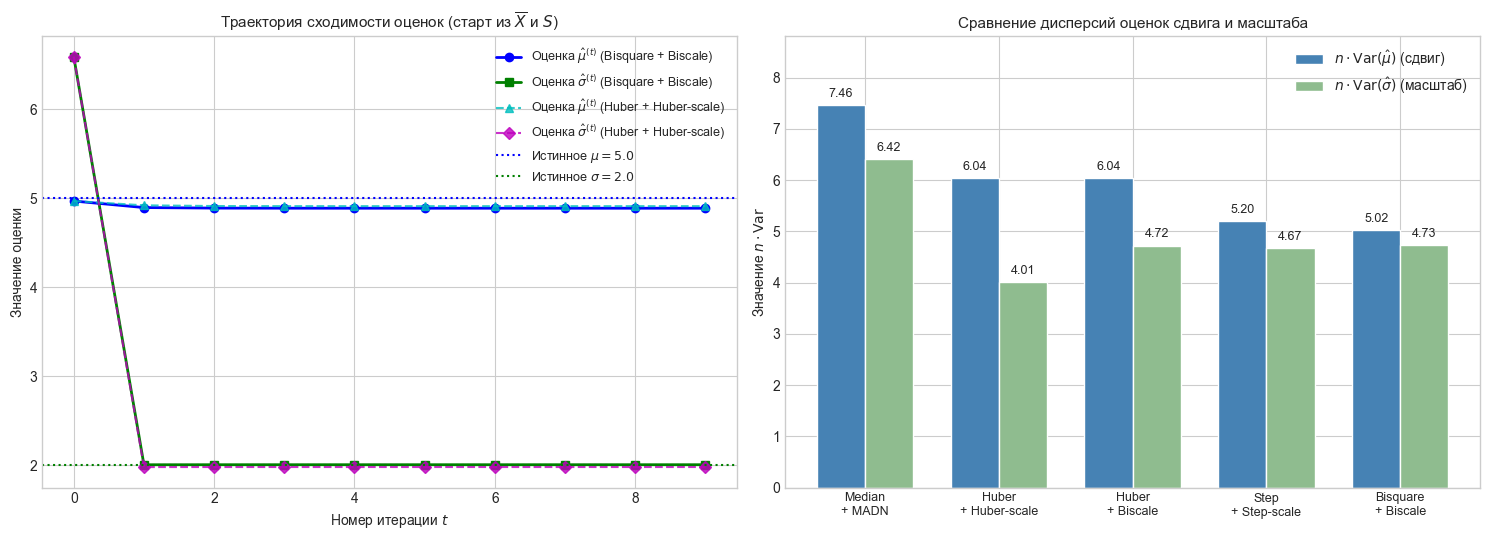

In [46]:
labels_list = [p[0] for p in selected_pairs]
n_var_mu_list = [n_size_joint * np.var(mc_results[l]['mu']) for l in labels_list]
n_var_sig_list = [n_size_joint * np.var(mc_results[l]['sigma']) for l in labels_list]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Траектория сходимости метода при старте из выборочных (X_mean, S)
init_mu_val = np.mean(x_dirty)
init_sigma_val = np.std(x_dirty, ddof=1)
_, _, hist_m_huber, hist_s_huber = joint_m_estimator(
    x_dirty, weight_huber, 1.345, rho_huber_scale, K_HUBER_S, DELTA_MOD_HUBER,
    init_mu=init_mu_val, init_sigma=init_sigma_val
)
_, _, hist_m_bisq, hist_s_bisq = joint_m_estimator(
    x_dirty, weight_bisquare, 4.685, rho_biscale, K_BISCALE, DELTA_MOD_BISCALE,
    init_mu=init_mu_val, init_sigma=init_sigma_val
)

axes[0].plot(range(len(hist_m_bisq)), hist_m_bisq, 'bo-', lw=2, label='Оценка $\\hat{\\mu}^{(t)}$ (Bisquare + Biscale)')
axes[0].plot(range(len(hist_s_bisq)), hist_s_bisq, 'gs-', lw=2, label='Оценка $\\hat{\\sigma}^{(t)}$ (Bisquare + Biscale)')
axes[0].plot(range(len(hist_m_huber)), hist_m_huber, 'c^--', alpha=0.8, label='Оценка $\\hat{\\mu}^{(t)}$ (Huber + Huber-scale)')
axes[0].plot(range(len(hist_s_huber)), hist_s_huber, 'mD--', alpha=0.8, label='Оценка $\\hat{\\sigma}^{(t)}$ (Huber + Huber-scale)')
axes[0].axhline(MU_TRUE, color='blue', linestyle=':', lw=1.5, label=f'Истинное $\\mu = {MU_TRUE}$')
axes[0].axhline(SIGMA_TRUE, color='green', linestyle=':', lw=1.5, label=f'Истинное $\\sigma = {SIGMA_TRUE}$')
axes[0].set_title('Траектория сходимости оценок (старт из $\\overline{X}$ и $S$)', fontsize=11)
axes[0].set_xlabel('Номер итерации $t$')
axes[0].set_ylabel('Значение оценки')
axes[0].legend(loc='upper right', fontsize=9)

# Столбчатая диаграмма n*Var(mu_hat) и n*Var(sigma_hat)
x_pos = np.arange(len(labels_list))
width = 0.36

bars1 = axes[1].bar(x_pos - width/2, n_var_mu_list, width, label='$n \\cdot \\text{Var}(\\hat{\\mu})$ (сдвиг)', color='steelblue')
bars2 = axes[1].bar(x_pos + width/2, n_var_sig_list, width, label='$n \\cdot \\text{Var}(\\hat{\\sigma})$ (масштаб)', color='darkseagreen')

for bar in bars1:
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2.0, h + 0.1, f"{h:.2f}", ha='center', va='bottom', fontsize=9)
for bar in bars2:
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2.0, h + 0.1, f"{h:.2f}", ha='center', va='bottom', fontsize=9)

axes[1].set_title('Сравнение дисперсий оценок сдвига и масштаба', fontsize=11)
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels([l.replace(" + ", "\n+ ") for l in labels_list], fontsize=9)
axes[1].set_ylabel('Значение $n \\cdot \\text{Var}$')
axes[1].set_ylim(0, max(n_var_mu_list) * 1.18)
axes[1].legend()

plt.tight_layout()
plt.show()